In [5237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5238]:
df=pd.read_csv("used_cars_trainingdata (1).csv")

In [5239]:
df.head()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [5240]:
df.tail()

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
7248,7248,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54 kmpl,1598 CC,103.6 bhp,5.0,NaN,NaN
7249,7249,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7250,7250,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08 kmpl,1461 CC,63.1 bhp,5.0,NaN,NaN
7251,7251,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.2 kmpl,1197 CC,103.6 bhp,5.0,NaN,NaN
7252,7252,Mercedes-Benz E-Class 2009-2013 E 220 CDI Avan...,Kochi,2014,72443,Diesel,Automatic,First,10.0 kmpl,2148 CC,170 bhp,5.0,NaN,NaN


In [5241]:
df.columns

Index(['S.No.', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type',
       'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats',
       'New_Price', 'Price'],
      dtype='str')

In [5242]:
df.isna().sum()

S.No.                   0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 46
Power                  46
Seats                  53
New_Price            6247
Price                1234
dtype: int64

In [5243]:
df.dtypes

S.No.                  int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
dtype: object

In [5244]:
df["Location"].value_counts()

Location
Mumbai        949
Hyderabad     876
Coimbatore    772
Kochi         772
Pune          765
Delhi         660
Kolkata       654
Chennai       591
Jaipur        499
Bangalore     440
Ahmedabad     275
Name: count, dtype: int64

In [5245]:
df["Location"].unique()

<ArrowStringArray>
[    'Mumbai',       'Pune',    'Chennai', 'Coimbatore',  'Hyderabad',
     'Jaipur',      'Kochi',    'Kolkata',      'Delhi',  'Bangalore',
  'Ahmedabad']
Length: 11, dtype: str

In [5246]:
df["Location"].nunique()

11

In [5247]:
df2=df["Fuel_Type"].value_counts()
df2

Fuel_Type
Diesel      3852
Petrol      3325
CNG           62
LPG           12
Electric       2
Name: count, dtype: int64

In [5248]:
df["Fuel_Type"].unique()

<ArrowStringArray>
['CNG', 'Diesel', 'Petrol', 'LPG', 'Electric']
Length: 5, dtype: str

In [5249]:
df["Fuel_Type"].nunique()

5

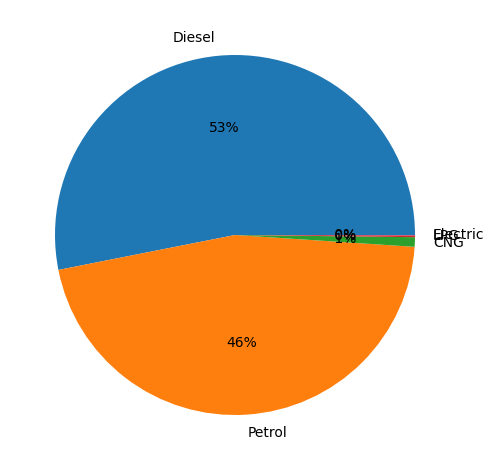

In [5250]:
plt.pie(df2.values,labels=df2.index,autopct="%2.f%%")
plt.tight_layout()

In [5251]:
df["Owner_Type"].value_counts()

Owner_Type
First             5952
Second            1152
Third              137
Fourth & Above      12
Name: count, dtype: int64

In [5252]:
df["Owner_Type"].unique()

<ArrowStringArray>
['First', 'Second', 'Fourth & Above', 'Third']
Length: 4, dtype: str

In [5253]:
df["Owner_Type"].nunique()

4

In [5254]:
df["Name"].nunique()

2041

In [5255]:
# ADD NEW COLUMN==> BRAND USE LAMBDA FUNCTION
df["Brand"]=df["Name"].apply(lambda x:x.split()[0])

In [5256]:
df.columns

Index(['S.No.', 'Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type',
       'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats',
       'New_Price', 'Price', 'Brand'],
      dtype='str')

In [5257]:
df.dtypes

S.No.                  int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
Brand                    str
dtype: object

In [5258]:
df_d=pd.get_dummies(df[["Location","Fuel_Type","Transmission","Owner_Type","New_Price"]],drop_first=True,dtype=int)
df_d

,Location_Bangalore,Location_Chennai,Location_Coimbatore,Location_Delhi,Location_Hyderabad,Location_Jaipur,Location_Kochi,Location_Kolkata,Location_Mumbai,Location_Pune,...,New_Price_9.99 Lakh,New_Price_91.23 Lakh,New_Price_91.38 Lakh,New_Price_92.01 Lakh,New_Price_92.5 Lakh,New_Price_92.79 Lakh,New_Price_95.04 Lakh,New_Price_95.13 Lakh,New_Price_95.38 Lakh,New_Price_99.92 Lakh
0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7248,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7249,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
7250,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
7251,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [5259]:
# df+df_d concat 
df_e=pd.concat([df,df_d],axis=1)
df_e

,S.No.,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,...,New_Price_9.99 Lakh,New_Price_91.23 Lakh,New_Price_91.38 Lakh,New_Price_92.01 Lakh,New_Price_92.5 Lakh,New_Price_92.79 Lakh,New_Price_95.04 Lakh,New_Price_95.13 Lakh,New_Price_95.38 Lakh,New_Price_99.92 Lakh
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,...,0,0,0,0,0,0,0,0,0,0
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,...,0,0,0,0,0,0,0,0,0,0
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,...,0,0,0,0,0,0,0,0,0,0
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,...,0,0,0,0,0,0,0,0,0,0
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7248,7248,Volkswagen Vento Diesel Trendline,Hyderabad,2011,89411,Diesel,Manual,First,20.54 kmpl,1598 CC,...,0,0,0,0,0,0,0,0,0,0
7249,7249,Volkswagen Polo GT TSI,Mumbai,2015,59000,Petrol,Automatic,First,17.21 kmpl,1197 CC,...,0,0,0,0,0,0,0,0,0,0
7250,7250,Nissan Micra Diesel XV,Kolkata,2012,28000,Diesel,Manual,First,23.08 kmpl,1461 CC,...,0,0,0,0,0,0,0,0,0,0
7251,7251,Volkswagen Polo GT TSI,Pune,2013,52262,Petrol,Automatic,Third,17.2 kmpl,1197 CC,...,0,0,0,0,0,0,0,0,0,0


In [5260]:
df_e.drop(columns=["S.No.","Name","Location","Fuel_Type","Transmission","Owner_Type","New_Price"],inplace=True)


In [5261]:
df_e["Mileage"]=df_e["Mileage"].str.replace("kmpl","")
df_e["Mileage"]=df_e["Mileage"].str.replace("km/kg","")

In [5262]:
df_e["Mileage"]=df_e["Mileage"].astype("float")
df_e["Mileage"]

0       26.60
1       19.67
2       18.20
3       20.77
4       15.20
        ...  
7248    20.54
7249    17.21
7250    23.08
7251    17.20
7252    10.00
Name: Mileage, Length: 7253, dtype: float64

In [5263]:
df_e["Power"]=df_e["Power"].str.replace("bhp","")

In [5264]:
df_e["Engine"]=df_e["Engine"].str.replace("CC","")

In [5265]:
df_e["Engine"]=df_e["Engine"].astype("float")

In [5266]:
df_e.loc[df_e.Power=="null ","Power"]=np.nan

In [5267]:
df_e["Power"]=df_e["Power"].astype("float")

In [5268]:
df.isna().sum()

S.No.                   0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 46
Power                  46
Seats                  53
New_Price            6247
Price                1234
Brand                   0
dtype: int64

In [5269]:
df_e["Mileage"]=df_e["Mileage"].fillna(df_e["Mileage"].mean())

In [5270]:
df_e["Engine"]=df_e["Engine"].fillna(df_e["Engine"].mean())

In [5271]:
df_e["Power"]=df_e["Power"].fillna(df_e["Power"].mode()[0])

In [5272]:
df_e["Seats"]=df_e["Seats"].fillna(df_e["Seats"].mode()[0])

In [5273]:
df_e["Price"]=df_e["Price"].fillna(df_e["Price"].mean())

In [5274]:
df_e.shape

(7253, 650)

In [5275]:
df_e.columns

Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'Price', 'Brand', 'Location_Bangalore', 'Location_Chennai',
       ...
       'New_Price_9.99 Lakh', 'New_Price_91.23 Lakh', 'New_Price_91.38 Lakh',
       'New_Price_92.01 Lakh', 'New_Price_92.5 Lakh', 'New_Price_92.79 Lakh',
       'New_Price_95.04 Lakh', 'New_Price_95.13 Lakh', 'New_Price_95.38 Lakh',
       'New_Price_99.92 Lakh'],
      dtype='str', length=650)

In [5276]:
x=df_e.drop(columns=["Price"])
y=df_e["Price"]
x


,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Brand,Location_Bangalore,Location_Chennai,Location_Coimbatore,...,New_Price_9.99 Lakh,New_Price_91.23 Lakh,New_Price_91.38 Lakh,New_Price_92.01 Lakh,New_Price_92.5 Lakh,New_Price_92.79 Lakh,New_Price_95.04 Lakh,New_Price_95.13 Lakh,New_Price_95.38 Lakh,New_Price_99.92 Lakh
0,2010,72000,26.60,998.0,58.16,5.0,Maruti,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2015,41000,19.67,1582.0,126.20,5.0,Hyundai,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2011,46000,18.20,1199.0,88.70,5.0,Honda,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,2012,87000,20.77,1248.0,88.76,7.0,Maruti,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,2013,40670,15.20,1968.0,140.80,5.0,Audi,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7248,2011,89411,20.54,1598.0,103.60,5.0,Volkswagen,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7249,2015,59000,17.21,1197.0,103.60,5.0,Volkswagen,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7250,2012,28000,23.08,1461.0,63.10,5.0,Nissan,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7251,2013,52262,17.20,1197.0,103.60,5.0,Volkswagen,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5277]:
y

0        1.750000
1       12.500000
2        4.500000
3        6.000000
4       17.740000
          ...    
7248     9.479468
7249     9.479468
7250     9.479468
7251     9.479468
7252     9.479468
Name: Price, Length: 7253, dtype: float64

In [5278]:
x=pd.get_dummies(x,columns=["Brand"],drop_first=True,dtype=int)

In [5279]:
test_df=pd.read_csv("used_cars_testdata_cleaned.csv")

In [5280]:
test_df.head()

,S.No.,Year,Kilometers_Driven,Transmission,Owner_Type,Mileage,Engine,Power,Seats
0,2954,2016,30000,Manual,First,20.4 kmpl,1197 CC,81.80 bhp,5.0
1,6520,2016,105000,Manual,Second,23.2 kmpl,1248 CC,73.94 bhp,5.0
2,6036,2009,140000,Manual,First,13.8 kmpl,1399 CC,68 bhp,5.0
3,6251,2014,33750,Manual,First,15.6 kmpl,1196 CC,70.02 bhp,5.0
4,6735,2017,35000,Manual,First,24.3 kmpl,1248 CC,88.5 bhp,5.0


In [5281]:
test_df.shape

(1451, 9)

In [5282]:
test_df.isnull().sum()

S.No.                 0
Year                  0
Kilometers_Driven     0
Transmission          0
Owner_Type            0
Mileage               0
Engine               11
Power                11
Seats                12
dtype: int64

In [5283]:

test_df["Engine"]=test_df["Engine"].str.replace("CC","")
test_df["Engine"]

0       1197 
1       1248 
2       1399 
3       1196 
4       1248 
        ...  
1446    1197 
1447    2993 
1448    1248 
1449    1248 
1450    1396 
Name: Engine, Length: 1451, dtype: str

In [5284]:
test_df["Engine"]=test_df["Engine"].astype("float")

In [5285]:
test_df["Engine"]=test_df["Engine"].fillna(test_df["Engine"].mean())

In [5286]:
test_df["Power"]=test_df["Power"].str.replace("bhp","")



In [5287]:
test_df.loc[test_df.Power=='null ',"Power"]=np.nan

In [5288]:
test_df["Power"]=test_df["Power"].astype("float")
test_df["Power"]

0        81.80
1        73.94
2        68.00
3        70.02
4        88.50
         ...  
1446     82.00
1447    258.00
1448     73.90
1449     88.50
1450     88.70
Name: Power, Length: 1451, dtype: float64

In [5289]:
test_df["Power"]=test_df["Power"].fillna(test_df["Power"].mode()[0])

In [5290]:
test_df["Seats"]=test_df["Seats"].fillna(test_df["Seats"].mode()[0])

In [5291]:
test_df.dtypes

S.No.                  int64
Year                   int64
Kilometers_Driven      int64
Transmission             str
Owner_Type               str
Mileage                  str
Engine               float64
Power                float64
Seats                float64
dtype: object

In [5292]:
test_df["Mileage"]=test_df["Mileage"].str.replace("kmpl","")
test_df['Mileage']=test_df["Mileage"].str.replace("km/kg","")


In [5293]:
test_df["Mileage"]=test_df["Mileage"].astype("float")

In [5294]:
test_df=pd.get_dummies(test_df,columns=["Transmission","Owner_Type"],drop_first=True,dtype=int)
test_df.columns

Index(['S.No.', 'Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power',
       'Seats', 'Transmission_Manual', 'Owner_Type_Fourth & Above',
       'Owner_Type_Second', 'Owner_Type_Third'],
      dtype='str')

In [5295]:
test_df.drop(columns=["S.No."],inplace=True)

In [5296]:
test_df.columns

Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'Transmission_Manual', 'Owner_Type_Fourth & Above', 'Owner_Type_Second',
       'Owner_Type_Third'],
      dtype='str')

In [5297]:
x.columns

Index(['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats',
       'Location_Bangalore', 'Location_Chennai', 'Location_Coimbatore',
       'Location_Delhi',
       ...
       'Brand_Nissan', 'Brand_OpelCorsa', 'Brand_Porsche', 'Brand_Renault',
       'Brand_Skoda', 'Brand_Smart', 'Brand_Tata', 'Brand_Toyota',
       'Brand_Volkswagen', 'Brand_Volvo'],
      dtype='str', length=680)

In [5298]:
y

0        1.750000
1       12.500000
2        4.500000
3        6.000000
4       17.740000
          ...    
7248     9.479468
7249     9.479468
7250     9.479468
7251     9.479468
7252     9.479468
Name: Price, Length: 7253, dtype: float64

In [5299]:
x_train=x[test_df.columns]

In [5300]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [5301]:
model.fit(x_train,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.85, 0. ,-0.06,...,-0. ,-0.19, 0.13]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Year','Kilometers_Driven','Mileage',...,'Owner_Type_Fourth & Above', 'Owner_Type_Second','Owner_Type_Third']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1709
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [5302]:
y_pred=model.predict(test_df)
y_pred

array([7.13609922, 6.40078843, 1.18084503, ..., 2.40097108, 9.37551756,
       7.46839612], shape=(1451,))

In [5303]:
from sklearn.metrics import r2_score

In [5304]:
y_train_pred=model.predict(x_train)
print(r2_score(y,y_train_pred))

0.5777817211924596
